# Megaline | Mobile Plan Classification

## 1. Business Context

Megaline, a mobile telecommunications provider, aims to improve its customer plan recommendations by identifying subscribers whose usage patterns align with its two current offerings: Smart and Ultra.

The company has access to historical subscriber behavior data, including monthly call activity, call duration, messaging volume, and mobile internet consumption.

This project explores the use of supervised machine learning to identify behavioral patterns associated with each subscription plan and develop a classification model capable of predicting the plan currently used by a subscriber.

## 2. Business Objective

Develop a classification model that predicts whether a subscriber belongs to the Smart or Ultra plan based on their monthly usage patterns.

The primary performance metric is **Accuracy**, with a minimum acceptance threshold of **0.75**.

The final model will be evaluated on an independent test dataset to assess its ability to generalize to previously unseen observations.

## 3. Analytical Approach

The project follows a structured machine learning workflow:

1. **Data inspection:** assess dataset structure, variable types, distributions, and data quality.
2. **Data preparation:** define predictor variables and the target variable, then partition the dataset into training, validation, and test subsets.
3. **Model development:** train and evaluate Decision Tree, Random Forest, and Logistic Regression classifiers.
4. **Hyperparameter optimization:** investigate alternative model configurations using validation accuracy.
5. **Model evaluation:** assess the selected model on the independent test dataset.
6. **Sanity check:** compare the model's performance against a simple baseline to verify that its predictions provide meaningful predictive value.

## 4. Dataset Overview

The analysis uses the `users_behavior.csv` dataset, which contains monthly subscriber usage information.

| Feature | Description |
|---|---|
| `calls` | Number of calls made |
| `minutes` | Total call duration in minutes |
| `messages` | Number of text messages sent |
| `mb_used` | Mobile internet consumption in MB |
| `is_ultra` | Target variable: 0 = Smart, 1 = Ultra |

## 5. Success Criteria

The project will be considered successful if the selected classification model achieves an accuracy of at least **0.75** on the independent test dataset.

Beyond meeting this threshold, model selection will consider validation performance, generalization, and the practical value of the resulting predictions.

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define a single random seed used throughout the project
RANDOM_STATE = 12345

# Load the dataset
df = pd.read_csv('Datasets/users_behavior.csv')

# Display the first observations
display(df.head())

,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0


## 6. Initial Data Exploration

We begin by examining the overall structure of the dataset to understand its dimensions, variable types, and available information.

We will also verify that the columns match the features described in the project brief and that the target variable is properly identified.

This exploration allows us to confirm whether the data is ready for training machine learning models.

In [2]:
# Inspect dataset dimensions
print('Dataset dimensions:')
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

# Inspect data types and non-null counts
print('\nGeneral information:')
df.info()

# Display column names
print('\nAvailable columns:')
print(df.columns.tolist())

Dataset dimensions:
Rows: 3214
Columns: 5

General information:
<class 'pandas.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB

Available columns:
['calls', 'minutes', 'messages', 'mb_used', 'is_ultra']


### Dataset Structure Analysis

Based on the output above, we review the number of records and variables available, as well as the data types of each column.

We also verify that all predictor features are numeric and that the target variable `is_ultra` is properly formatted for training.

**Key findings:**

- **Total observations:** 3,214 monthly subscriber records.
- **Available variables:** 5 columns (`calls`, `minutes`, `messages`, `mb_used`, and `is_ultra`).
- **Data types:** 4 continuous/numeric features stored as `float64` and 1 binary integer target (`int64`).
- **Missing values:** 0 missing values across all columns (`3,214 non-null` entries each).

The dataset structure is clean and requires no type conversion or missing-value imputation before modeling.

In [3]:
# Obtain descriptive statistics
display(df.describe())

# Check for missing values
print('Missing values per column:')
print(df.isna().sum())

# Check for duplicate records
print('\nNumber of duplicate records:')
print(df.duplicated().sum())

# Review target variable distribution
print('\nTarget variable distribution:')
print(df['is_ultra'].value_counts())

# Review class proportions
print('\nClass proportions:')
print(df['is_ultra'].value_counts(normalize=True))

,calls,minutes,messages,mb_used,is_ultra
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,63.038892,438.208787,38.281269,17207.673836,0.306472
std,33.236368,234.569872,36.148326,7570.968246,0.461100
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.000000,274.575000,9.000000,12491.902500,0.000000
50%,62.000000,430.600000,30.000000,16943.235000,0.000000
75%,82.000000,571.927500,57.000000,21424.700000,1.000000
max,244.000000,1632.060000,224.000000,49745.730000,1.000000


Missing values per column:
calls       0
minutes     0
messages    0
mb_used     0
is_ultra    0
dtype: int64

Number of duplicate records:
0

Target variable distribution:
is_ultra
0    2229
1     985
Name: count, dtype: int64

Class proportions:
is_ultra
0    0.693528
1    0.306472
Name: proportion, dtype: float64


## 7. Data Preparation

After inspecting the structure and quality of the dataset (confirming **0 missing values** and **0 duplicate rows**), we prepare the data for model training. Note that the target variable shows an imbalanced distribution: **69.35% Smart (`0`, 2,229 users)** and **30.65% Ultra (`1`, 985 users)**.

We separate the predictor features from the target variable:

- **Features (X):** `calls`, `minutes`, `messages`, and `mb_used`.
- **Target variable (y):** `is_ultra` (`0` = Smart plan, `1` = Ultra plan).

Next, we split the data into three independent subsets using stratified sampling to preserve class proportions across all partitions: **60% training**, **20% validation**, and **20% test**.

In [4]:
# Separate predictor features and target variable
features = df.drop('is_ultra', axis=1)
target = df['is_ultra']

# Display dimensions of each set
print('Features dimensions:')
print(features.shape)

print('\nTarget variable dimensions:')
print(target.shape)

# Display the first observations
display(features.head())
display(target.head())

Features dimensions:
(3214, 4)

Target variable dimensions:
(3214,)


,calls,minutes,messages,mb_used
0,40.0,311.90,83.0,19915.42
1,85.0,516.75,56.0,22696.96
2,77.0,467.66,86.0,21060.45
3,106.0,745.53,81.0,8437.39
4,66.0,418.74,1.0,14502.75


0    0
1    0
2    0
3    1
4    0
Name: is_ultra, dtype: int64

In [5]:
# First split: 80% for training and validation, 20% for testing
features_train_valid, features_test, target_train_valid, target_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=target
)

# Second split: 75% of the 80% (60% total) for training, 25% of the 80% (20% total) for validation
features_train, features_valid, target_train, target_valid = train_test_split(
    features_train_valid,
    target_train_valid,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=target_train_valid
)

print('Data splitting completed.')

Data splitting completed.


In [6]:
# Display dimensions of each subset
print('Training set:')
print(features_train.shape)

print('\nValidation set:')
print(features_valid.shape)

print('\nTest set:')
print(features_test.shape)

# Calculate subset percentages
total = len(df)

print('\nSplit percentages:')
print(f'Training: {len(features_train) / total:.2%}')
print(f'Validation: {len(features_valid) / total:.2%}')
print(f'Test: {len(features_test) / total:.2%}')

# Verify class distribution across subsets
print('\nClass distribution - Training:')
print(target_train.value_counts(normalize=True))

print('\nClass distribution - Validation:')
print(target_valid.value_counts(normalize=True))

print('\nClass distribution - Test:')
print(target_test.value_counts(normalize=True))

Training set:
(1928, 4)

Validation set:
(643, 4)

Test set:
(643, 4)

Split percentages:
Training: 59.99%
Validation: 20.01%
Test: 20.01%

Class distribution - Training:
is_ultra
0    0.693465
1    0.306535
Name: proportion, dtype: float64

Class distribution - Validation:
is_ultra
0    0.693624
1    0.306376
Name: proportion, dtype: float64

Class distribution - Test:
is_ultra
0    0.693624
1    0.306376
Name: proportion, dtype: float64


## 8. Model Training and Validation

In this stage, we train and tune three classification algorithms to determine which one delivers the strongest predictive performance when recommending Smart and Ultra plans.

We evaluate all candidates using **Accuracy**, which measures the proportion of correct predictions out of total predictions:

1. **Decision Tree Classifier:** evaluate maximum tree depths (`max_depth`) from 1 to 15 to control model complexity, recording both training and validation accuracy.
2. **Random Forest Classifier:** evaluate combinations of tree counts (`n_estimators`) and maximum depths (`max_depth`).
3. **Logistic Regression:** train a standardized linear classifier using a `StandardScaler` pipeline and compare several values of the inverse regularization strength (`C`).

All models are fit exclusively on the training set (`1,928` rows) and compared on the validation set (`643` rows) to identify the configuration that exceeds the **0.75** accuracy threshold.

In [7]:
# Train and evaluate Decision Trees across different maximum depths

tree_results = []

for depth in range(1, 16):
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE
    )

    model.fit(features_train, target_train)

    # Accuracy on the training set and on the validation set
    train_accuracy = accuracy_score(target_train, model.predict(features_train))
    valid_accuracy = accuracy_score(target_valid, model.predict(features_valid))

    tree_results.append({
        'max_depth': depth,
        'train_accuracy': train_accuracy,
        'valid_accuracy': valid_accuracy,
        'train_valid_gap': train_accuracy - valid_accuracy
    })

# Create a DataFrame with the results
tree_results_df = pd.DataFrame(tree_results)

# Sort results from highest to lowest validation accuracy
tree_results_df = tree_results_df.sort_values(
    by='valid_accuracy',
    ascending=False
).reset_index(drop=True)

# Display results
display(tree_results_df)

# Identify the best configuration
best_tree_depth = int(tree_results_df.loc[0, 'max_depth'])
best_tree_accuracy = tree_results_df.loc[0, 'valid_accuracy']

print(f'Best depth: {best_tree_depth}')
print(f'Best validation accuracy: {best_tree_accuracy:.4f}')

# Train the best Decision Tree model
best_tree_model = DecisionTreeClassifier(
    max_depth=best_tree_depth,
    random_state=RANDOM_STATE
)

best_tree_model.fit(features_train, target_train)

,max_depth,train_accuracy,valid_accuracy,train_valid_gap
0,5,0.820021,0.816485,0.003536
1,9,0.874481,0.811820,0.062662
2,7,0.846473,0.807154,0.039319
3,11,0.896784,0.807154,0.089630
4,8,0.858402,0.805599,0.052804
5,10,0.884336,0.805599,0.078737
6,3,0.794087,0.804044,-0.009956
7,4,0.798237,0.804044,-0.005807
8,6,0.835062,0.802488,0.032574
9,13,0.925311,0.786936,0.138375


Best depth: 5
Best validation accuracy: 0.8165


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",12345
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Decision Tree Model Analysis

We evaluated 15 Decision Tree configurations by varying `max_depth` from 1 to 15 levels, recording both the training and the validation accuracy of each configuration so that the effect of tree complexity can be inspected directly.

**Results obtained:**

- **Best depth:** `5`, with a validation accuracy of `0.8165` (`81.65%`). Its training accuracy is `0.8200`, so the gap between the two sets is only `0.0035`.
- **Underfitting:** very shallow trees (`max_depth` = 1–2) reach only `0.7589` and `0.7838` on the validation set, and their training accuracy is just as low (`0.7521` and `0.7822`). A model that scores low on both sets is too simple to capture the usage patterns.
- **Overfitting:** trees with `max_depth` = 12–15 reach a training accuracy of `0.9155`–`0.9585` but only `0.7792`–`0.7869` on the validation set, a gap of `0.130`–`0.179`. They memorize the training data instead of learning patterns that generalize.
- The pattern across depths is not a clean curve: depths 9 and 11 (`0.8118` and `0.8072`) score higher than depths 6 and 8 (`0.8025` and `0.8056`).

The validation accuracies of depths 3 through 11 span only about `0.014`, roughly nine validation observations out of `643`. Depth 5 is therefore best described as the top performer among several comparable configurations, and it comfortably exceeds the `0.75` requirement.

In [8]:
# Train and evaluate Random Forest models across different hyperparameters

forest_results = []

for n_estimators in [10, 30, 50, 100]:
    for depth in [2, 4, 6, 8, 10, None]:

        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=depth,
            random_state=RANDOM_STATE
        )

        model.fit(features_train, target_train)

        predictions = model.predict(features_valid)

        accuracy = accuracy_score(target_valid, predictions)

        forest_results.append({
            'n_estimators': n_estimators,
            'max_depth': depth,
            'accuracy': accuracy
        })

# Create a DataFrame with the results
forest_results_df = pd.DataFrame(forest_results)

# Sort results by accuracy
forest_results_df = forest_results_df.sort_values(
    by='accuracy',
    ascending=False
).reset_index(drop=True)

# Display top configurations
display(forest_results_df.head(10))

# Display the full grid of validation accuracy to see how neighboring configurations behave
accuracy_grid = forest_results_df.copy()
accuracy_grid['max_depth'] = accuracy_grid['max_depth'].apply(
    lambda depth: 'None' if pd.isna(depth) else str(int(depth))
)
accuracy_grid = accuracy_grid.pivot(
    index='n_estimators',
    columns='max_depth',
    values='accuracy'
)[['2', '4', '6', '8', '10', 'None']]

print('\nValidation accuracy by configuration (rows: n_estimators, columns: max_depth):')
display(accuracy_grid.round(4))

# Selection rule: a difference smaller than one validation observation is not meaningful,
# so among the configurations within one observation of the best score we keep the largest forest
top_accuracy = forest_results_df['accuracy'].max()
one_observation = 1 / len(target_valid)

near_best = forest_results_df[
    forest_results_df['accuracy'] >= top_accuracy - one_observation - 1e-9
].sort_values(
    by=['n_estimators', 'accuracy'],
    ascending=False
).reset_index(drop=True)

print('\nConfigurations within one validation observation of the best score:')
display(near_best)

# Train the selected Random Forest configuration
selected_depth = None if pd.isna(near_best.loc[0, 'max_depth']) else int(near_best.loc[0, 'max_depth'])

best_forest_params = {
    'n_estimators': int(near_best.loc[0, 'n_estimators']),
    'max_depth': selected_depth
}

best_forest_model = RandomForestClassifier(
    n_estimators=best_forest_params['n_estimators'],
    max_depth=best_forest_params['max_depth'],
    random_state=RANDOM_STATE
)

best_forest_model.fit(features_train, target_train)

best_forest_accuracy = accuracy_score(
    target_valid,
    best_forest_model.predict(features_valid)
)

print('Selected Random Forest configuration:')
print(best_forest_params)

print(f'Validation accuracy: {best_forest_accuracy:.4f}')
print(f'Highest validation accuracy in the grid: {top_accuracy:.4f}')

,n_estimators,max_depth,accuracy
0,10,8.0,0.832037
1,30,8.0,0.830482
2,50,6.0,0.824261
3,30,6.0,0.822706
4,50,8.0,0.821151
5,10,4.0,0.821151
6,100,6.0,0.821151
7,100,10.0,0.821151
8,100,8.0,0.821151
9,50,10.0,0.819596



Validation accuracy by configuration (rows: n_estimators, columns: max_depth):


max_depth,2,4,6,8,10,None
n_estimators,,,,,,
10,0.7823,0.8212,0.8149,0.8320,0.8103,0.8134
30,0.7932,0.8149,0.8227,0.8305,0.8134,0.8165
50,0.7885,0.8180,0.8243,0.8212,0.8196,0.8165
100,0.7932,0.8180,0.8212,0.8212,0.8212,0.8134



Configurations within one validation observation of the best score:


,n_estimators,max_depth,accuracy
0,30,8.0,0.830482
1,10,8.0,0.832037


Selected Random Forest configuration:
{'n_estimators': 30, 'max_depth': 8}
Validation accuracy: 0.8305
Highest validation accuracy in the grid: 0.8320


### Random Forest Model Analysis

To evaluate the Random Forest classifier, we tested 24 hyperparameter combinations across four values of `n_estimators` (`10`, `30`, `50`, and `100`) and six values of `max_depth` (`2`, `4`, `6`, `8`, `10`, and `None`).

By aggregating predictions across multiple trees, the ensemble reduces variance compared to a single Decision Tree and improves generalization on unseen validation records.

**Results obtained:**

- **Number of trees (`n_estimators`):** `30`.
- **Maximum depth (`max_depth`):** `8`.
- **Validation accuracy:** `0.8305` (`83.05%`).

This configuration outperforms the single Decision Tree (`0.8165`) by `1.40` percentage points on the validation set.

**How the configuration was chosen:** the highest validation accuracy in the grid (`0.8320`) belongs to a forest of only 10 trees with `max_depth=8`. The forest with 30 trees and the same depth scores `0.8305`, only `0.0016` lower, which is a single validation observation (1 out of `643`). The ten best configurations span only about `0.012` of validation accuracy (roughly eight observations). Differences this small are within sampling noise, and a forest with very few trees tends to be less stable, so we applied a simple rule that uses only validation data: among the configurations within one validation observation of the best score, keep the largest forest. The accuracy grid also shows that `max_depth=8` gives the best validation accuracy with 10 and 30 trees and stays within `0.004` of the best depth with 50 and 100 trees, so the choice of depth is consistent across neighboring configurations.

In [9]:
# Tune the regularization strength (C) of Logistic Regression.
# The scaler stays inside the pipeline, so it is fitted on the training data only.

logistic_results = []

best_logistic_accuracy = 0
best_logistic_model = None
best_logistic_params = None

for c_value in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            C=c_value,
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ])

    # Fit the model
    model.fit(features_train, target_train)

    # Generate predictions on the validation set
    predictions = model.predict(features_valid)

    # Calculate validation accuracy
    accuracy = accuracy_score(target_valid, predictions)

    logistic_results.append({
        'C': c_value,
        'accuracy': accuracy
    })

    # Ties keep the first (more strongly regularized) configuration
    if accuracy > best_logistic_accuracy:
        best_logistic_accuracy = accuracy
        best_logistic_model = model
        best_logistic_params = {'C': c_value}

# Display the results for every value of C
logistic_results_df = pd.DataFrame(logistic_results)
display(logistic_results_df)

# Keep the best configuration for the model comparison
logistic_model = best_logistic_model
logistic_accuracy = best_logistic_accuracy

print('Logistic Regression Results:')
print(f'Best configuration: {best_logistic_params}')
print(f'Validation accuracy: {logistic_accuracy:.4f}')

,C,accuracy
0,0.01,0.743390
1,0.10,0.749611
2,1.00,0.754277
3,10.00,0.755832
4,100.00,0.755832


Logistic Regression Results:
Best configuration: {'C': 10}
Validation accuracy: 0.7558


### Logistic Regression Model Analysis

We trained a Logistic Regression classifier using the four usage features to predict each subscriber's plan.

Before fitting the linear model, features were standardized via `StandardScaler` inside a `Pipeline` so that variables measured on vastly different scales (such as `mb_used` in the tens of thousands versus `calls` in the tens) contribute evenly to gradient optimization without data leakage.

To make the comparison with the tree-based models fairer, we also varied the inverse regularization strength `C` over `0.01`, `0.1`, `1`, `10`, and `100` (default `lbfgs` solver) and kept the value with the highest validation accuracy.

**Results obtained:**

- Validation accuracy rises from `0.7434` with `C=0.01` to `0.7481` with `C=0.1` and reaches `0.7558` (`75.58%`) with `C=1`. It stays at `0.7558` for `C=10` and `C=100`.
- The best configuration is therefore `C=1`, which is the default value: tuning the regularization strength did not improve on the default model.

Even at its best, Logistic Regression only barely clears the `0.75` threshold and stays between `6.1` and `7.5` percentage points below the tree-based models. Since it is a linear model, a plausible explanation is that the relationship between usage and plan is not linear. This project does not test that hypothesis directly, so we treat it as an interpretation rather than a finding.

In [10]:
# Create a comparison table with the best validation results

model_comparison = pd.DataFrame([
    {
        'model': 'Decision Tree',
        'accuracy': best_tree_accuracy
    },
    {
        'model': 'Random Forest',
        'accuracy': best_forest_accuracy
    },
    {
        'model': 'Logistic Regression',
        'accuracy': logistic_accuracy
    }
])

# Sort models from highest to lowest accuracy
model_comparison = model_comparison.sort_values(
    by='accuracy',
    ascending=False
).reset_index(drop=True)

# Display comparison
display(model_comparison)

# Identify the top-performing model
print('Model with highest validation accuracy:')
print(model_comparison.iloc[0]['model'])

print(
    f"Accuracy: {model_comparison.iloc[0]['accuracy']:.4f}"
)

,model,accuracy
0,Random Forest,0.830482
1,Decision Tree,0.816485
2,Logistic Regression,0.755832


Model with highest validation accuracy:
Random Forest
Accuracy: 0.8305


### Model Comparison and Selection

After training and tuning all three algorithms, we consolidated their validation accuracy scores to select the strongest candidate.

**Validation comparison results:**

- **Random Forest (`n_estimators=30`, `max_depth=8`):** `0.8305` (`83.05%`).
- **Decision Tree (`max_depth=5`):** `0.8165` (`81.65%`).
- **Logistic Regression (`C=1`):** `0.7558` (`75.58%`).

**Random Forest** achieves the highest validation accuracy (`0.8305`), exceeding the `0.75` acceptance threshold by `8.05` percentage points. We select this model for final evaluation on the held-out test set.

In [11]:
# Create a dictionary with trained models and their validation accuracies
trained_models = {
    'Decision Tree': {
        'model': best_tree_model,
        'accuracy': best_tree_accuracy
    },
    'Random Forest': {
        'model': best_forest_model,
        'accuracy': best_forest_accuracy
    },
    'Logistic Regression': {
        'model': logistic_model,
        'accuracy': logistic_accuracy
    }
}

# Select the model with the highest validation accuracy
best_model_name = max(
    trained_models,
    key=lambda name: trained_models[name]['accuracy']
)

best_model = trained_models[best_model_name]['model']

best_model_valid_accuracy = trained_models[best_model_name]['accuracy']

print('SELECTED MODEL')
print('--------------')
print(f'Model: {best_model_name}')
print(f'Validation accuracy: {best_model_valid_accuracy:.4f}')

# Verify whether the model exceeds the required threshold
if best_model_valid_accuracy >= 0.75:
    print('\nThe model exceeds the minimum accuracy threshold.')
else:
    print('\nThe model does not meet the minimum accuracy threshold.')

SELECTED MODEL
--------------
Model: Random Forest
Validation accuracy: 0.8305

The model exceeds the minimum accuracy threshold.


## 9. Final Model Evaluation

Once the best-performing model has been selected using the validation dataset, we proceed to its final evaluation.

The test dataset (`643` observations) has remained completely separate throughout model development and hyperparameter selection. This ensures that the final assessment provides an unbiased estimate of the model's predictive performance.

The selected model will generate predictions for the test observations, and its performance will be assessed using:

- **Accuracy:** overall proportion of correct predictions.
- **Confusion Matrix:** distribution of correct and incorrect classifications across both subscription plans.
- **Classification Report:** precision, recall, and F1-score for each class.

In [12]:

# Generate predictions using the selected classification model
test_predictions = best_model.predict(features_test)

# Calculate final test accuracy
test_accuracy = accuracy_score(target_test, test_predictions)

print(f'Selected model: {best_model_name}')
print(f'Validation accuracy: {best_model_valid_accuracy:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')


Selected model: Random Forest
Validation accuracy: 0.8305
Test accuracy: 0.8165


### Final Accuracy Assessment

The selected Random Forest model was evaluated on the independent test set to measure its generalization performance on previously unseen subscribers.

**Evaluation results:**

- **Selected model:** Random Forest (`n_estimators=30`, `max_depth=8`).
- **Validation accuracy:** `0.8305` (`83.05%`).
- **Test accuracy:** `0.8165` (`81.65%`).
- **Minimum required accuracy:** `0.7500` (`75.00%`).

The model achieves **81.65%** accuracy on the test dataset, comfortably exceeding the `0.75` project requirement by `6.65` percentage points while exhibiting only a minor `1.40` percentage point drop from validation.

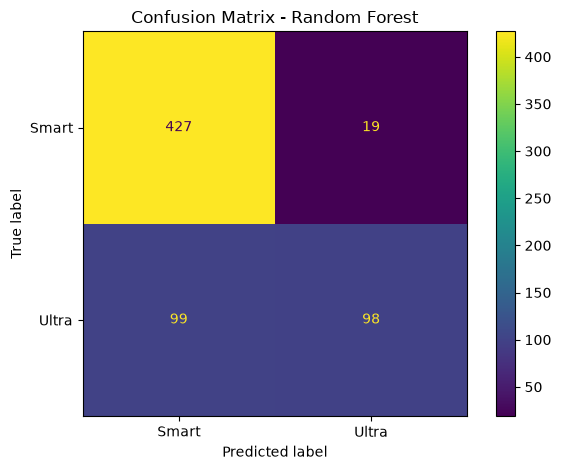

In [13]:

# Calculate classification outcomes
conf_matrix = confusion_matrix(
    target_test,
    test_predictions,
    labels=[0, 1]
)

# Display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix,
    display_labels=['Smart', 'Ultra']
)

display_matrix.plot(values_format='d')

plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()


### Confusion Matrix Analysis

The confusion matrix breaks down the model's predictions on the 643 test subscribers into four outcomes:

- **True Negatives (TN = 427):** Smart subscribers correctly classified as Smart.
- **False Positives (FP = 19):** Smart subscribers incorrectly classified as Ultra.
- **False Negatives (FN = 99):** Ultra subscribers incorrectly classified as Smart.
- **True Positives (TP = 98):** Ultra subscribers correctly classified as Ultra.

**Key findings:**

- The model identifies **Smart** subscribers with very high consistency (`427` out of `446` correctly classified, or `95.74%`), generating only `19` false positives.
- Most classification errors occur as **False Negatives (`99` of the `118` errors)**, where actual Ultra subscribers are classified as Smart. The usage comparison by outcome group shown after the classification report indicates that these subscribers use the service much like Smart subscribers.

In [14]:

# Generate class-level evaluation metrics
classification_results = classification_report(
    target_test,
    test_predictions,
    labels=[0, 1],
    target_names=['Smart', 'Ultra'],
    output_dict=True,
    zero_division=0
)

# Convert evaluation metrics into a structured DataFrame
classification_results_df = pd.DataFrame(
    classification_results
).T

display(classification_results_df.round(4))


,precision,recall,f1-score,support
Smart,0.8118,0.9574,0.8786,446.0000
Ultra,0.8376,0.4975,0.6242,197.0000
accuracy,0.8165,0.8165,0.8165,0.8165
macro avg,0.8247,0.7274,0.7514,643.0000
weighted avg,0.8197,0.8165,0.8007,643.0000


In [15]:
# Compare average usage across the four outcome groups of the test set
# (actual plan classified as predicted plan)
usage_columns = ['calls', 'minutes', 'messages', 'mb_used']

test_usage = features_test.copy()
test_usage['actual_plan'] = target_test.map({0: 'Smart', 1: 'Ultra'})
test_usage['predicted_plan'] = pd.Series(
    test_predictions,
    index=features_test.index
).map({0: 'Smart', 1: 'Ultra'})
test_usage['outcome_group'] = (
    test_usage['actual_plan'] + ' classified as ' + test_usage['predicted_plan']
)

usage_by_outcome = test_usage.groupby('outcome_group')[usage_columns].mean().round(2)
usage_by_outcome.insert(0, 'observations', test_usage['outcome_group'].value_counts())

display(usage_by_outcome)

,observations,calls,minutes,messages,mb_used
outcome_group,,,,,
Smart classified as Smart,427,56.75,390.51,33.48,15636.84
Smart classified as Ultra,19,85.53,581.61,53.58,22503.39
Ultra classified as Smart,99,61.26,428.18,31.24,15698.69
Ultra classified as Ultra,98,85.85,597.12,55.16,22863.00


### Class-Level Performance Analysis

Reviewing precision, recall, and F1-score separately for Smart and Ultra highlights how class imbalance (`69.36%` Smart vs. `30.64%` Ultra in the test set) affects classification behavior:

- **Smart (`0`, support = 446):** Precision = `0.8118`, Recall = `0.9574`, F1-score = `0.8786`.
- **Ultra (`1`, support = 197):** Precision = `0.8376`, Recall = `0.4975`, F1-score = `0.6242`.
- **Macro average:** Precision = `0.8247`, Recall = `0.7274`, F1-score = `0.7514`.
- **Weighted average:** Precision = `0.8197`, Recall = `0.8165`, F1-score = `0.8007`.

**Key findings:**

- **High precision across both plans (~81–84%):** When the model recommends Smart it is correct `81.18%` of the time, and when it recommends Ultra it is correct `83.76%` of the time, roughly 4 out of 5 times.
- **Asymmetric recall:** The model captures `95.74%` of actual Smart users but only `49.75%` of actual Ultra users, so it still identifies about half of the Ultra subscribers correctly.
- **Usage by outcome group (table above):** the `99` Ultra subscribers classified as Smart use on average `15,698.69` MB and send `31.24` messages per month, almost the same as the Smart subscribers classified correctly (`15,636.84` MB and `33.48` messages) and far below the Ultra subscribers classified correctly (`22,863.00` MB and `55.16` messages). The same pattern appears in calls (`61.26` vs. `56.75` vs. `85.85`) and minutes (`428.18` vs. `390.51` vs. `597.12`). This supports the explanation that the missed Ultra subscribers have usage that overlaps with Smart usage. Conversely, the `19` Smart subscribers classified as Ultra use `22,503.39` MB on average, close to the correctly identified Ultra group.
- The minority status of the Ultra class may also contribute to its lower recall, but we did not test that here.

## 10. Sanity Check and Baseline Comparison

A sanity check is performed to verify that the selected model provides meaningful predictive value beyond a naive classification rule.

We establish a baseline using a `DummyClassifier` with `strategy='most_frequent'`, which always predicts the majority class (`Smart = 0`) without learning any relationship between subscriber usage and subscription plans.

In [16]:

# Configure the majority-class baseline
baseline_model = DummyClassifier(
    strategy='most_frequent'
)

# Fit the baseline using the training dataset
baseline_model.fit(features_train, target_train)

# Generate predictions for the independent test dataset
baseline_predictions = baseline_model.predict(features_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    target_test,
    baseline_predictions
)

print('Baseline Model Performance')
print('--------------------------')
print(f'Baseline accuracy: {baseline_accuracy:.4f}')
print(f'Selected model accuracy: {test_accuracy:.4f}')


Baseline Model Performance
--------------------------
Baseline accuracy: 0.6936
Selected model accuracy: 0.8165


In [17]:

# Consolidate final evaluation results
final_comparison = pd.DataFrame([
    {
        'model': 'Selected Machine Learning Model',
        'accuracy': test_accuracy
    },
    {
        'model': 'Majority-Class Baseline',
        'accuracy': baseline_accuracy
    }
])

# Calculate the performance improvement over the baseline
accuracy_improvement = test_accuracy - baseline_accuracy

display(final_comparison)

print('\nFinal Evaluation Summary')
print('------------------------')
print(f'Selected model: {best_model_name}')
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Baseline accuracy: {baseline_accuracy:.4f}')
print(f'Accuracy improvement: {accuracy_improvement:.4f}')

# Verify the project's acceptance criteria
print('\nProject Acceptance Criteria')

if test_accuracy >= 0.75:
    print('PASS: Minimum accuracy requirement achieved.')
else:
    print('FAIL: Minimum accuracy requirement not achieved.')

if test_accuracy > baseline_accuracy:
    print('PASS: Model outperforms the majority-class baseline.')
else:
    print('FAIL: Model does not outperform the baseline.')


,model,accuracy
0,Selected Machine Learning Model,0.816485
1,Majority-Class Baseline,0.693624



Final Evaluation Summary
------------------------
Selected model: Random Forest
Test accuracy: 0.8165
Baseline accuracy: 0.6936
Accuracy improvement: 0.1229

Project Acceptance Criteria
PASS: Minimum accuracy requirement achieved.
PASS: Model outperforms the majority-class baseline.


## 11. Diagnostic and Behavioral Analysis

### 11.1. Prediction Confidence Analysis

Beyond evaluating binary accuracy, we examine the predicted class probabilities (`predict_proba`) on the validation dataset to assess how confident the selected model is when assigning subscription plans.

In [18]:

# Generate class probabilities for validation observations
validation_probabilities = best_model.predict_proba(features_valid)

# Store predicted probabilities alongside actual and predicted classes
validation_confidence = pd.DataFrame({
    'actual_plan': target_valid,
    'predicted_plan': best_model.predict(features_valid),
    'smart_probability': validation_probabilities[:, 0],
    'ultra_probability': validation_probabilities[:, 1],
    'prediction_confidence': validation_probabilities.max(axis=1)
})

# Identify whether each prediction is correct
validation_confidence['correct_prediction'] = (
    validation_confidence['actual_plan']
    == validation_confidence['predicted_plan']
)

display(validation_confidence.head(10))

print(
    f"Average prediction confidence: "
    f"{validation_confidence['prediction_confidence'].mean():.4f}"
)


,actual_plan,predicted_plan,smart_probability,ultra_probability,prediction_confidence,correct_prediction
580,1,0,0.796670,0.203330,0.796670,False
2272,1,0,0.797484,0.202516,0.797484,False
1415,1,0,0.790518,0.209482,0.790518,False
1356,0,0,0.867497,0.132503,0.867497,True
1910,0,0,0.630939,0.369061,0.630939,True
3149,0,0,0.831998,0.168002,0.831998,True
1785,0,0,0.867118,0.132882,0.867118,True
1651,0,0,0.881156,0.118844,0.881156,True
2109,1,0,0.759765,0.240235,0.759765,False
2214,0,1,0.299276,0.700724,0.700724,False


Average prediction confidence: 0.8121


### Prediction Confidence Interpretation

Examining the predicted probabilities on the validation set (`643` observations) gives a first idea of how decisively the Random Forest assigns each subscriber to a plan. Here, confidence is the highest class probability assigned by the model, which is not the same as the probability that the prediction is correct.

**Key findings:**

- **Average prediction confidence:** `0.8121` (`81.21%` maximum class probability across all validation predictions).
- The first ten validation rows shown above have confidence values between about `0.63` and `0.88`. This is only a small illustrative sample; the distribution over all `643` observations is analyzed next.

,count,mean,median,std
Incorrect predictions,109,0.7634,0.7858,0.1117
Correct predictions,534,0.8220,0.8547,0.1028


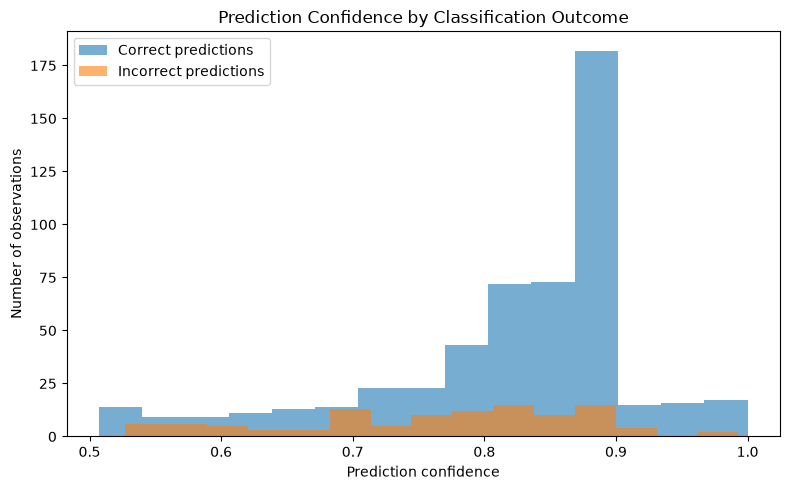

In [19]:

# Compare confidence distributions for correct and incorrect predictions
confidence_summary = (
    validation_confidence
    .groupby('correct_prediction')['prediction_confidence']
    .agg(['count', 'mean', 'median', 'std'])
)

confidence_summary.index = [
    'Incorrect predictions',
    'Correct predictions'
]

display(confidence_summary.round(4))

# Visualize prediction confidence by classification outcome
plt.figure(figsize=(8, 5))

for outcome, label in [
    (True, 'Correct predictions'),
    (False, 'Incorrect predictions')
]:
    values = validation_confidence.loc[
        validation_confidence['correct_prediction'] == outcome,
        'prediction_confidence'
    ]

    if not values.empty:
        plt.hist(
            values,
            bins=15,
            alpha=0.6,
            label=label
        )

plt.title('Prediction Confidence by Classification Outcome')
plt.xlabel('Prediction confidence')
plt.ylabel('Number of observations')
plt.legend()
plt.tight_layout()
plt.show()


### Confidence Distribution Analysis

Comparing predicted probabilities between correct and incorrect classifications on the validation dataset:

- **Correct predictions (`534` cases, `83.05%`):** Mean confidence = `0.8220`, Median = `0.8547`, Std = `0.1028`.
- **Incorrect predictions (`109` cases, `16.95%`):** Mean confidence = `0.7634`, Median = `0.7858`, Std = `0.1117`.

**Key findings:**

- Correct predictions have somewhat higher confidence, but the difference is modest: the gap between the group means (about `0.059`) is smaller than the standard deviation of either group (`0.103`–`0.112`), and the two distributions overlap heavily in the histogram.
- The model often makes mistakes with high confidence: `46` of the `109` incorrect predictions (`42.2%`) have a confidence of at least `0.80`, and `29` (`26.6%`) have at least `0.85`. The confidence of the incorrect predictions spans almost the entire range, from `0.53` to `0.99`. The predicted probability alone is therefore not a reliable signal for telling apart trustworthy predictions from errors.

calls               minutes                 messages                \
        mean median    std    mean  median     std     mean median    std   
Smart  58.46   60.0  25.94  405.94  410.56  184.51    33.38   28.0  28.23   
Ultra  73.39   74.0  43.92  511.22  502.55  308.03    49.36   38.0  47.80   

        mb_used                      
           mean    median       std  
Smart  16208.47  16506.93   5870.50  
Ultra  19468.82  19308.01  10087.18

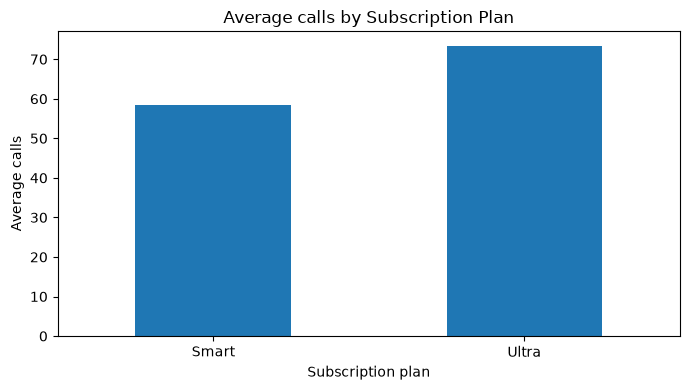

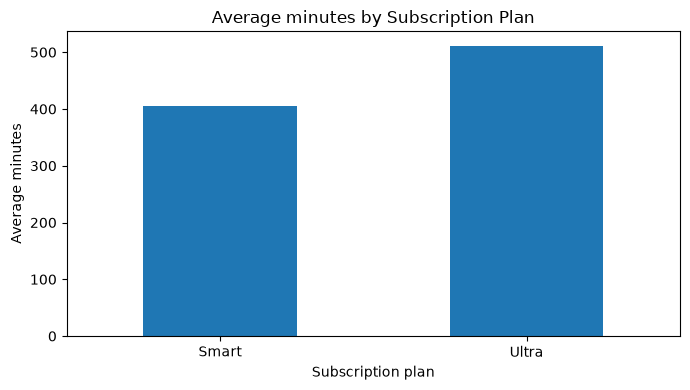

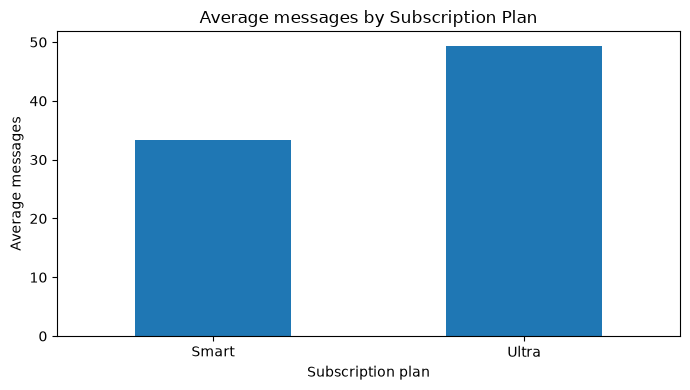

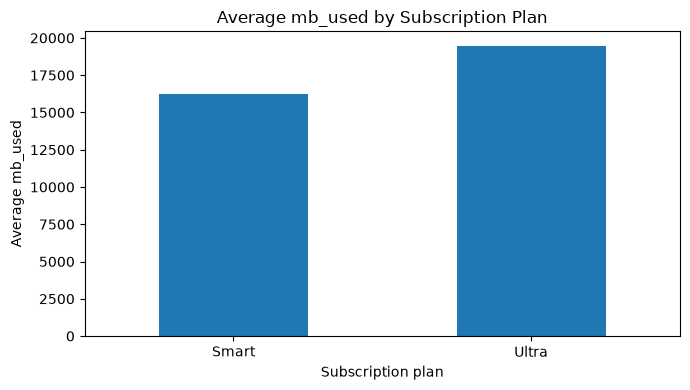

In [20]:

# Calculate mean, median, and standard deviation of usage by subscription plan
usage_profile = (
    df.groupby('is_ultra')[
        ['calls', 'minutes', 'messages', 'mb_used']
    ]
    .agg(['mean', 'median', 'std'])
)

usage_profile.index = ['Smart', 'Ultra']

display(usage_profile.round(2))

# Compare average usage across subscription plans
average_usage = df.groupby('is_ultra')[
    ['calls', 'minutes', 'messages', 'mb_used']
].mean()

average_usage.index = ['Smart', 'Ultra']

# Create a comparison chart for each usage feature
for feature in average_usage.columns:
    plt.figure(figsize=(7, 4))

    average_usage[feature].plot(
        kind='bar',
        rot=0
    )

    plt.title(f'Average {feature} by Subscription Plan')
    plt.xlabel('Subscription plan')
    plt.ylabel(f'Average {feature}')
    plt.tight_layout()
    plt.show()


### 11.2. Subscriber Usage Profile Analysis

Comparing mean, median, and standard deviation of monthly usage across plans shows which behavioral features differ between Smart and Ultra subscribers:

| Plan | Calls (Mean / Median) | Minutes (Mean / Median) | Messages (Mean / Median) | MB Used (Mean / Median) |
|---|---|---|---|---|
| **Smart** | 58.46 / 60.00 | 405.94 / 410.56 | 33.38 / 28.00 | 16,208.47 / 16,506.93 |
| **Ultra** | 73.39 / 74.00 | 511.22 / 502.55 | 49.36 / 38.00 | 19,468.82 / 19,308.01 |

| Plan | Calls (Std) | Minutes (Std) | Messages (Std) | MB Used (Std) |
|---|---|---|---|---|
| **Smart** | 25.94 | 184.51 | 28.23 | 5,870.50 |
| **Ultra** | 43.92 | 308.03 | 47.80 | 10,087.18 |

**Key findings:**

- **Higher consumption across all metrics for Ultra users:** Ultra subscribers average **25.5% more calls** (`73.39` vs. `58.46`), **25.9% more minutes** (`511.22` vs. `405.94`), **47.9% more messages** (`49.36` vs. `33.38`), and **20.1% more mobile data** (`19,468.82 MB` vs. `16,208.47 MB`).
- **Substantial overlap between plans:** for every variable, the gap between the plan means is smaller than the standard deviation of either plan. For example, the difference in `mb_used` is `3,260.35` MB, while the standard deviations are `5,870.50` MB (Smart) and `10,087.18` MB (Ultra). No single variable can therefore separate the two plans cleanly.
- **Ultra usage is more dispersed:** the standard deviation of Ultra subscribers is about `1.7` times that of Smart subscribers for all four variables.
- **Interpretation (not tested here):** a plausible explanation for the stronger performance of the tree-based models over Logistic Regression is that the relationship between usage and plan is not linear. This project does not test that hypothesis directly.

,feature,importance_mean,importance_std
0,mb_used,0.1144,0.0132
1,minutes,0.0518,0.0104
2,messages,0.0516,0.0060
3,calls,0.0355,0.0059


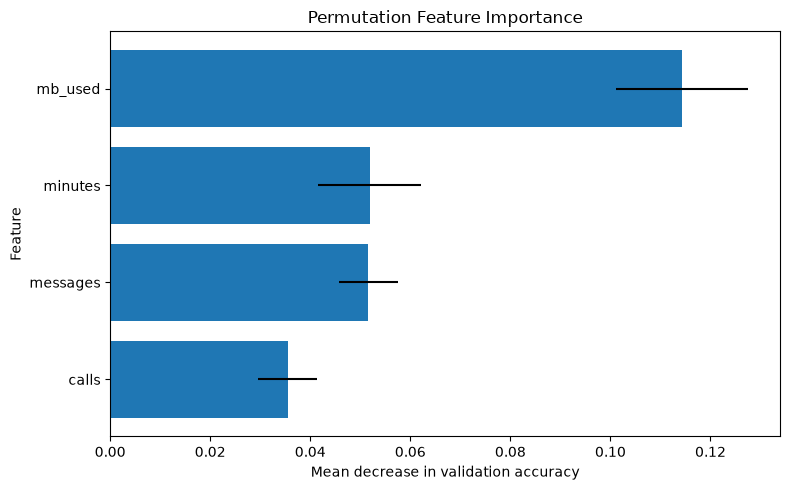

,calls,minutes,messages,mb_used
calls,1.00,0.98,0.18,0.29
minutes,0.98,1.00,0.17,0.28
messages,0.18,0.17,1.00,0.20
mb_used,0.29,0.28,0.20,1.00


In [21]:


# Estimate feature importance using validation accuracy
permutation_result = permutation_importance(
    best_model,
    features_valid,
    target_valid,
    scoring='accuracy',
    n_repeats=15,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Organize feature importance estimates
feature_importance = pd.DataFrame({
    'feature': features.columns,
    'importance_mean': permutation_result.importances_mean,
    'importance_std': permutation_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by='importance_mean',
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

# Visualize feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['feature'][::-1],
    feature_importance['importance_mean'][::-1],
    xerr=feature_importance['importance_std'][::-1]
)

plt.title('Permutation Feature Importance')
plt.xlabel('Mean decrease in validation accuracy')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Check how strongly the usage variables are correlated with each other
# (relevant when interpreting permutation importance)
display(features.corr().round(2))


### 11.3. Feature Importance Interpretation

Permutation importance (`n_repeats=15`) quantifies how much validation accuracy drops when each predictor's values are randomly shuffled:

| Rank | Feature | Mean Accuracy Decrease | Std Dev |
|---|---|---|---|
| 1 | `mb_used` | `0.1144` | `0.0132` |
| 2 | `minutes` | `0.0518` | `0.0104` |
| 3 | `messages` | `0.0516` | `0.0060` |
| 4 | `calls` | `0.0355` | `0.0059` |

**Key findings:**

- **Mobile internet consumption (`mb_used`) is the strongest predictor:** Shuffling `mb_used` reduces validation accuracy by **11.44 percentage points** on average, more than twice the drop caused by any other feature.
- **Call duration (`minutes`) and messaging (`messages`) provide secondary signal:** Shuffling them lowers accuracy by `5.18` and `5.16` percentage points, respectively. Their difference (`0.0002`) is far smaller than their standard deviations, so their relative order should not be interpreted.
- **Call count (`calls`) has the smallest contribution (`3.55` percentage points):** The correlation matrix printed after the chart shows that `calls` and `minutes` are almost perfectly correlated (`0.98`), while the other pairs are correlated at `0.17`–`0.29`. A plausible explanation is that, when one of the two is shuffled, the model can partly rely on the other, so permutation importance splits the credit between them. This remains an interpretation, because we did not run an experiment that removes one of the two variables.

### 11.4. Consolidated Results Summary

The table below gathers the headline figures of the project in a single place, so that a reader can check the final result without going back through Sections 8 to 10. Its values are the ones derived and discussed in those sections; no new quantity is computed here.

In [22]:

# Consolidate the main model evaluation results
project_summary = pd.DataFrame({
    'metric': [
        'Selected model',
        'Validation accuracy',
        'Test accuracy',
        'Majority-class baseline accuracy',
        'Accuracy improvement over baseline',
        'Minimum accuracy requirement',
        'Acceptance criterion achieved',
        'Baseline outperformed'
    ],
    'result': [
        best_model_name,
        round(best_model_valid_accuracy, 4),
        round(test_accuracy, 4),
        round(baseline_accuracy, 4),
        round(accuracy_improvement, 4),
        0.75,
        test_accuracy >= 0.75,
        test_accuracy > baseline_accuracy
    ]
})

display(project_summary)

# Display the final model performance assessment
print('\nFINAL MODEL PERFORMANCE')
print('========================')
print(f'Model: {best_model_name}')
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Baseline accuracy: {baseline_accuracy:.4f}')

if test_accuracy >= 0.75 and test_accuracy > baseline_accuracy:
    print('\nThe model meets both evaluation criteria.')
elif test_accuracy >= 0.75:
    print('\nThe model meets the accuracy threshold but does not outperform the baseline.')
elif test_accuracy > baseline_accuracy:
    print('\nThe model outperforms the baseline but does not meet the accuracy threshold.')
else:
    print('\nThe model does not meet the evaluation criteria.')


,metric,result
0,Selected model,Random Forest
1,Validation accuracy,0.8305
2,Test accuracy,0.8165
3,Majority-class baseline accuracy,0.6936
4,Accuracy improvement over baseline,0.1229
5,Minimum accuracy requirement,0.75
6,Acceptance criterion achieved,True
7,Baseline outperformed,True



FINAL MODEL PERFORMANCE
Model: Random Forest
Test accuracy: 0.8165
Baseline accuracy: 0.6936

The model meets both evaluation criteria.


## 12. Model Reliability and Generalization

### 12.1. Generalization Assessment

A key consideration when evaluating a classification model is its ability to maintain consistent performance on previously unseen data.

The validation and test results provide two independent indicators of generalization performance. A substantial difference between these scores may suggest overfitting, while similar results indicate that the model performs consistently across different data subsets.

In [23]:
# Compare validation and test accuracy of the selected model,
# reusing the values computed earlier instead of recalculating them
generalization_gap = best_model_valid_accuracy - test_accuracy

print(f"Validation accuracy: {best_model_valid_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Generalization gap: {generalization_gap:.4f}")

if abs(generalization_gap) <= 0.02:
    print("The model shows a relatively small performance gap.")
elif abs(generalization_gap) <= 0.05:
    print("The model shows a moderate performance gap.")
else:
    print("The model shows a noticeable performance gap that deserves attention.")

Validation accuracy: 0.8305
Test accuracy: 0.8165
Generalization gap: 0.0140
The model shows a relatively small performance gap.


### 12.2. Interpretation of Generalization Results

Comparing validation accuracy (`0.8305`) against independent test accuracy (`0.8165`) yields a **generalization gap of `0.0140` (`1.40` percentage points)**, which the code above classifies as a relatively small gap (below the `0.02` cutoff).

This modest gap suggests that the selected Random Forest generalizes reasonably well to unseen subscriber records, and its test accuracy remains well above the `0.75` threshold. Three cautions apply when reading the gap:

- The selected configuration was chosen among 24 evaluated on the validation set, so its validation score may be slightly optimistic.
- With only `643` observations per subset, a difference of `1.40` percentage points corresponds to about nine observations and can be partly due to sampling noise.
- We did not compare validation-to-test gaps across configurations, so we cannot attribute the small gap specifically to the `max_depth=8` restriction.

## 13. Practical Considerations

### 13.1. Potential Business Application

The selected classification model can support Megaline's commercial and analytics teams by identifying usage patterns associated with the Smart and Ultra subscription plans:

- **Targeted plan migration campaigns:** Flagging Smart subscribers whose usage patterns consistently resemble Ultra profiles (`False Positives` in historical data) as prime candidates for upgrade offers.
- **Customer segmentation:** Grouping subscribers by predicted plan affinity and confidence scores to tailor marketing communications.
- **Decision-support tooling:** Serving as an analytical input alongside billing and tenure data rather than a fully automated billing rule.

### 13.2. Important Limitations

Before deploying the model in a production environment, several limitations should be noted:

- **Historical usage scope:** The model reflects past monthly behavior and may require periodic retraining if data consumption trends or plan allowances change.
- **Lower recall on Ultra subscribers (`49.75%`):** The model misses roughly half of the actual Ultra subscribers. The Ultra subscribers it misses average `15,698.69` MB and `31.24` messages per month, almost the same as correctly classified Smart subscribers (`15,636.84` MB and `33.48` messages), so their behavior in this dataset is hard to tell apart from Smart usage. Non-usage reasons for choosing Ultra (e.g., predictable billing or bundle preferences) cannot be assessed with the available data.
- **Limited feature set:** The dataset includes only four monthly usage aggregates and lacks demographic, tenure, device, or overage-fee variables.

### 13.3. Recommendations for Future Improvements

Future iterations of this classification pipeline could explore:

1. **Feature engineering:** Creating ratio and intensity features (such as `minutes_per_call`, `mb_per_day`, or threshold indicators relative to Smart plan limits of 500 minutes, 50 messages, and 15 GB).
2. **Class-weight and threshold tuning:** Adjusting probability thresholds or applying `class_weight='balanced'` if the business prioritizes higher recall on Ultra subscribers over overall accuracy.
3. **Gradient boosting models:** Benchmarking LightGBM, XGBoost, or CatBoost against Random Forest as richer behavioral and billing features become available.

### 14.1. Experimental Controls

The modeling workflow uses a single constant, `RANDOM_STATE = 12345`, defined in the first cell and passed to every step that involves randomness: the data partitions, the Decision Tree, Random Forest, and Logistic Regression models, and the permutation importance. The majority-class baseline (`DummyClassifier`) is deterministic and needs no seed. This makes the results reproducible and allows the seed to be changed in a single place.

Stratified splitting kept the class balance almost identical across partitions: approximately `69.35%` Smart in the training set (`60%` of the data) and `69.36%` Smart in the validation and test sets (`20%` each). The test set was only used after the final model had been selected, and the cell below verifies that the three subsets do not share any observations.

In [24]:
# Verify that the training, validation, and test sets do not share any observations
train_index = set(features_train.index)
valid_index = set(features_valid.index)
test_index = set(features_test.index)

print('Observations shared by training and validation sets:', len(train_index & valid_index))
print('Observations shared by training and test sets:', len(train_index & test_index))
print('Observations shared by validation and test sets:', len(valid_index & test_index))

# Verify that every observation was assigned to exactly one subset
print(f'\nObservations assigned to a subset: {len(train_index | valid_index | test_index)} of {len(df)}')

Observations shared by training and validation sets: 0
Observations shared by training and test sets: 0
Observations shared by validation and test sets: 0

Observations assigned to a subset: 3214 of 3214


### 14.2. Final Project Checklist

The following points summarize the methodological requirements addressed in this project:

- [x] Inspected dataset structure, descriptive statistics, and data quality (`0` missing values, `0` duplicates).
- [x] Separated predictor features (`calls`, `minutes`, `messages`, `mb_used`) and target variable (`is_ultra`).
- [x] Partitioned the dataset using stratified splits into training (`60%`), validation (`20%`), and test (`20%`) subsets.
- [x] Trained and tuned Decision Tree, Random Forest, and Logistic Regression classifiers.
- [x] Selected the final model (`Random Forest`, validation accuracy `0.8305`) using the validation set only, without touching the test set.
- [x] Evaluated the selected model on the independent test set (`0.8165` accuracy), exceeding the `0.75` threshold.
- [x] Verified predictive value via a majority-class baseline sanity check (`0.8165` vs. `0.6936`, a `+12.29` percentage point gain).
- [x] Conducted confusion matrix, precision/recall, prediction confidence, usage profile, and permutation importance diagnostics.

## 15. Final Conclusion

This project applied supervised machine learning techniques to classify Megaline subscribers into the **Smart** or **Ultra** mobile plans based on monthly usage behavior.

After comparing Decision Tree, Random Forest, and Logistic Regression classifiers across a stratified `60/20/20` train/validation/test split, a tuned **Random Forest Classifier (`n_estimators=30`, `max_depth=8`)** was selected. Its validation accuracy (`0.8305`) is within one validation observation of the best score in the grid (`0.8320`), and being a larger forest it is expected to be more stable than the top-scoring 10-tree forest.

- **Final test accuracy:** `0.8165` (`81.65%`)
- **Baseline accuracy (most frequent class):** `0.6936` (`69.36%`)
- **Acceptance threshold:** `0.7500` (`75.00%`)
- **Project outcome:** **PASS** — The model exceeds the `0.75` acceptance threshold by `6.65` percentage points and outperforms the majority-class baseline by `12.29` percentage points.

Behavioral and diagnostic analyses further indicated that mobile data usage (`mb_used`) is the most influential predictor of the subscription plan: shuffling it lowers validation accuracy by `11.44` percentage points, more than twice the drop of any other feature. The gap of `1.40` percentage points between validation and test accuracy suggests that the model generalizes reasonably well, which makes it suitable for supporting Megaline's targeted plan recommendation strategy.

The main limitation is the lower recall for Ultra subscribers: the model correctly identifies about `49.75%` of the actual Ultra subscribers (versus `95.74%` of the Smart subscribers), while its precision is `0.81` for Smart and `0.84` for Ultra. When the model predicts a plan it is therefore right roughly four times out of five, but around half of the Ultra subscribers are not flagged, and their usage is very similar to that of Smart subscribers.